# 04. Анализ ошибок и интерпретация модели

Вопросы:
1. Где модель ошибается сильнее всего: по уровню зарплаты, профессиям, источнику, опыту?
2. Почему возникают самые большие ошибки?
3. Какие слова и признаки модель считает признаками высокой и низкой зарплаты?
4. Где модели можно доверять, а где нет?

Чтобы ошибок было больше для анализа, используются прогнозы **вне выборки для всех 5 840 вакансий**:
данные делятся на 5 групп, и каждая группа предсказывается моделью, обученной на остальных четырёх.
Параметры модели взяты из ноутбука 03.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
import prep

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

meta = json.load(open("../models/final_model_meta.json"))
p, COLS = meta["params"], meta["features"]
C, N, B = prep.CAT_FEATURES, prep.NUM_FEATURES, prep.BOOL_FEATURES

def build(p):
    ct = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=p["min_freq"]), C),
        ("num", StandardScaler(), N + B),
        ("t", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, ngram_range=(1, p["word_ngram"]),
                              max_features=p["word_max"]), "full"),
        ("ti", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, analyzer="char_wb",
                               ngram_range=(2, p["char_max"])), "title"),
    ], transformer_weights={"ti": p["title_weight"]})
    return make_pipeline(ct, Ridge(alpha=p["alpha"]))

d = prep.labeled(prep.load())
d["oof"] = np.nan
for a, b in GroupKFold(5).split(d, groups=d["dup_group"]):
    d.loc[d.index[b], "oof"] = build(p).fit(d.iloc[a][COLS], d.iloc[a].y).predict(d.iloc[b][COLS])

d["real"] = np.exp(d["y"]); d["pred"] = np.exp(d["oof"])
d["err"] = (d["pred"] - d["real"]).abs()
d["rel"] = d["err"] / d["real"]
d["bias"] = (d["pred"] - d["real"]) / d["real"] * 100
print({k: round(v, 3) for k, v in prep.metrics(d["y"].values, d["oof"].values).items()})

{'MAE, сом': np.float64(15503.565), 'медианная ошибка, сом': np.float64(9389.667), 'MAPE, %': np.float64(34.622), 'доля ошибок < 20%': np.float64(0.412), 'R² (log)': np.float64(0.423)}


## 1. Ошибки по уровню зарплаты

`bias`: медианное отклонение прогноза в процентах (плюс = модель завышает).
`within20`: доля прогнозов с ошибкой меньше 20%.

In [2]:
def summary(col, order=None, min_n=30):
    g = d.groupby(col).agg(n=("rel", "size"), MAE=("err", "mean"), median_err=("err", "median"),
                           within20=("rel", lambda s: (s < .2).mean()), bias=("bias", "median"))
    g = g[g["n"] >= min_n]
    return g.reindex(order).dropna() if order else g
fmt = {"MAE": "{:,.0f}", "median_err": "{:,.0f}", "within20": "{:.0%}", "bias": "{:+.0f}%", "n": "{:,.0f}"}

d["band"] = pd.cut(d["real"], [0, 25_000, 40_000, 60_000, 100_000, 1e9],
                   labels=["<25k", "25–40k", "40–60k", "60–100k", "100k+"])
summary("band", ["<25k", "25–40k", "40–60k", "60–100k", "100k+"]).style.format(fmt)

,n,MAE,median_err,within20,bias
band,,,,,
<25k,"1,209","11,577","9,934",22%,+49%
25–40k,"2,189","7,616","5,800",55%,+9%
40–60k,"1,053","10,594","8,819",54%,-12%
60–100k,961,"23,602","22,719",30%,-30%
100k+,408,"63,054","56,146",16%,-45%


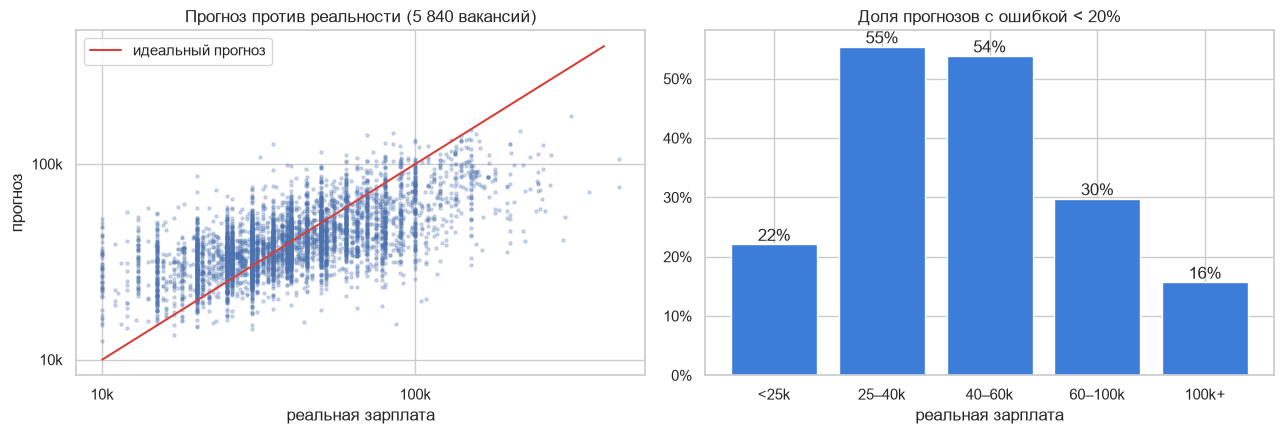

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(d["real"], d["pred"], s=5, alpha=.25)
ax[0].plot([10_000, 400_000], [10_000, 400_000], color="#d8403b", lw=1.5, label="идеальный прогноз")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].xaxis.set_major_formatter(K); ax[0].yaxis.set_major_formatter(K)
ax[0].set_xlabel("реальная зарплата"); ax[0].set_ylabel("прогноз"); ax[0].legend()
ax[0].set_title("Прогноз против реальности (5 840 вакансий)")
s = summary("band", ["<25k", "25–40k", "40–60k", "60–100k", "100k+"])
ax[1].bar(s.index.astype(str), s["within20"], color="#3b7dd8")
ax[1].yaxis.set_major_formatter(mt.PercentFormatter(1))
ax[1].set_title("Доля прогнозов с ошибкой < 20%"); ax[1].set_xlabel("реальная зарплата")
for i, v in enumerate(s["within20"]): ax[1].text(i, v, f"{v:.0%}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG + "04_bands.png", dpi=150); plt.show()

## 2. Ошибки по профессиям

In [4]:
prof = summary("sub_category", min_n=40).sort_values("within20")
print("Хуже всего предсказываются:")
display(prof.head(8).style.format(fmt))
print("Лучше всего предсказываются:")
display(prof.tail(8).style.format(fmt))

Хуже всего предсказываются:


,n,MAE,median_err,within20,bias
sub_category,,,,,
"Швея, портной, закройщик",256,"24,711","20,090",20%,-9%
Агент по недвижимости,52,"33,681","26,193",25%,-2%
"Программист, разработчик",74,"33,358","19,299",34%,+10%
Другое,444,"15,865","10,030",34%,+5%
"Секретарь, помощник руководителя, ассистент",47,"14,483","8,255",34%,-8%
"Уборщица, уборщик",274,"10,560","7,374",36%,+5%
Разнорабочий,82,"14,141","9,691",37%,+12%
Другие специальности,398,"15,433","10,136",37%,+2%


Лучше всего предсказываются:


,n,MAE,median_err,within20,bias
sub_category,,,,,
Зоотехник,50,"7,619","4,251",50%,+5%
"Повар, пекарь, кондитер",318,"10,911","7,408",51%,-1%
"Оператор call-центра, специалист контактного центра",123,"10,817","6,266",52%,+8%
"Продавец-консультант, продавец-кассир",336,"8,470","5,660",52%,-0%
"Наука, образование",108,"7,876","4,469",56%,+2%
Торговый представитель,205,"10,982","8,390",56%,-1%
Офис-менеджер,82,"7,710","4,118",61%,+2%
"Отели, кафе, рестораны",47,"12,430","9,503",64%,+7%


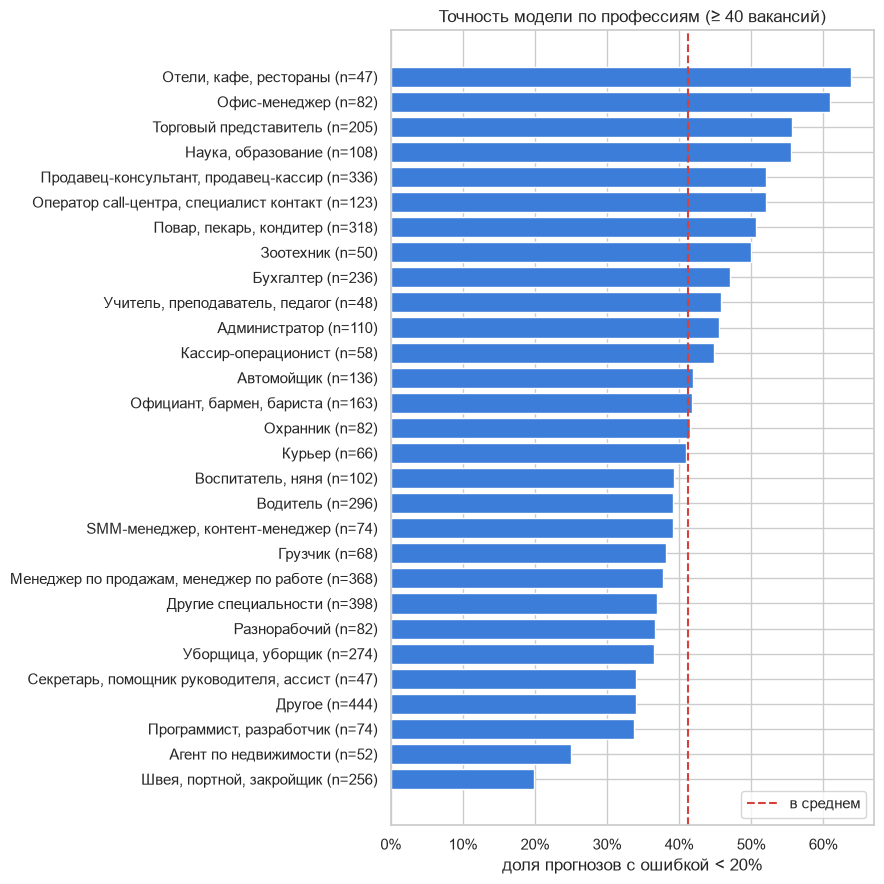

In [5]:
pr = prof.sort_values("within20")
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh([f"{i[:40]} (n={n})" for i, n in zip(pr.index, pr["n"])], pr["within20"], color="#3b7dd8")
ax.xaxis.set_major_formatter(mt.PercentFormatter(1)); ax.set_xlabel("доля прогнозов с ошибкой < 20%")
ax.axvline(d["rel"].lt(.2).mean(), color="#d8403b", ls="--", lw=1.5, label="в среднем")
ax.legend(loc="lower right"); ax.set_title("Точность модели по профессиям (≥ 40 вакансий)")
plt.tight_layout(); plt.savefig(FIG + "04_professions.png", dpi=150); plt.show()

## 3. Ошибки по источнику, опыту, городу и формату зарплаты

In [6]:
for col, order in [("source", None), ("experience", ["нет опыта", "1–3 года", "3–6 лет", "6+ лет"]),
                   ("city", None), ("pay_period", None), ("salary_type", None)]:
    print(f"--- {col}")
    display(summary(col, order).style.format(fmt))

--- source


,n,MAE,median_err,within20,bias
source,,,,,
headhunter,"2,028","17,448","9,957",42%,+2%
lalafo,"3,792","14,464","9,130",41%,+1%


--- experience


,n,MAE,median_err,within20,bias
experience,,,,,
нет опыта,"2,596","14,215","8,862",41%,+3%
1–3 года,"2,409","14,904","8,884",44%,+1%
3–6 лет,601,"21,634","13,157",37%,-4%
6+ лет,214,"20,664","14,513",33%,+7%


--- city


,n,MAE,median_err,within20,bias
city,,,,,
Бишкек,"5,039","15,410","9,354",42%,+1%
Ош,110,"18,377","9,262",36%,-0%
Регионы,671,"15,738","9,596",37%,+1%


--- pay_period


,n,MAE,median_err,within20,bias
pay_period,,,,,
day,"1,029","11,956","8,609",41%,+2%
month,"4,722","16,008","9,499",42%,+1%
week,65,"34,837","29,494",12%,-45%


--- salary_type


,n,MAE,median_err,within20,bias
salary_type,,,,,
from,"4,493","14,745","9,283",40%,+2%
range,"1,248","17,678","9,714",44%,-3%
to,79,"24,289","10,660",39%,-5%


## 4. Самые большие ошибки

20 вакансий, где прогноз дальше всего от реальности (в разах).

In [7]:
d["ratio"] = np.maximum(d["pred"] / d["real"], d["real"] / d["pred"])
worst = d.nlargest(20, "ratio")[["name", "source", "sub_category", "real", "pred", "pay_period", "requirements"]].copy()
worst["requirements"] = worst["requirements"].fillna("").str.replace(r"\s+", " ", regex=True).str.slice(0, 110)
worst["real"] = worst["real"].round(-2); worst["pred"] = worst["pred"].round(-2)
pd.set_option("display.max_colwidth", 110)
worst

,name,source,sub_category,real,pred,pay_period,requirements
5672,Интродьюсер инвестиционных продуктов,headhunter,Другое,295300.0,40900.0,month,Опыт работы в сфере продаж и консультирования по инвестиционным продуктам приветствуется. Желание развиват...
4407,Business Development Manager,headhunter,Руководитель отдела продаж,447400.0,76600.0,month,"Наличие устоявшихся бизнес-связей и персональных контактов с ключевыми лицами, принимающими решения в целе..."
4649,"В частный детский садик требуется, помощник воспитателя, график",lalafo,"Наука, образование",86600.0,15200.0,week,"В частный детский садик требуется, помощник воспитателя, график работы с 7.30 до 18.00, 5/2, суббота и вос..."
5656,Менеджер отдела продаж,headhunter,"Менеджер по продажам, менеджер по работе с клиентами",300000.0,53600.0,month,"Опыт работе менеджером по продажам - от 1 года (строительная сфера – преимущество, но не критично). Желате..."
1382,Менеджер по продажам. До 1 года опыта. Полный рабочий день,lalafo,"Менеджер по продажам, менеджер по работе с клиентами",223700.0,40500.0,month,Ищем опытного специалиста по продажам автомобилей в Бишкеке. От кандидата необходимо: - уверенное знание м...
5385,Оператор колл-центра (немецкий язык),headhunter,"Оператор call-центра, специалист контактного центра",195600.0,35400.0,month,"Вы быстро реагируете на ситуацию и работаете надежно и самостоятельно, даже из дома. Благодаря хорошему зн..."
845,Уборщица. Пишпек,lalafo,"Уборщица, уборщик",108200.0,20500.0,week,Требуется технички График 5/2 С воскресенья по четверг С 8 до 18:00 Завтраки и обеды за счет компании Ежен...
1563,Требуются опытные портные и технолог-закройщик в ателье зарплата,lalafo,Другие специальности,10000.0,52200.0,month,"Требуются опытные портные и технолог-закройщик в ателье , зарплата высокая"
1397,Парикмахер Универсал. Аренда места. Ошский рынок / базар,lalafo,Парикмахер,104000.0,20000.0,day,Сдаётся рабочия места парикмахера 7000с за месяц (есть стиральная машинка ) места для мастера маникюра 400...
5417,Швея Прямострочка,lalafo,"Швея, портной, закройщик",200000.0,39500.0,month,Срочно требуется швеи село Лебединовка оплата высокая


Типичные причины больших ошибок (по чтению этих объявлений):
- **редкие дорогие вакансии с обычным названием:** «менеджер отдела продаж» за 300 000,
  Business Development Manager за ~447 000, оператор колл-центра с немецким языком за ~196 000.
  Модель видит обычную должность и предсказывает обычную зарплату;
- **процент от продаж или инвестиций:** в объявлении указан потенциальный доход, а не оклад
  («интродьюсер инвестиционных продуктов» за ~295 000);
- **ошибки пересчёта периода оплаты:** недельные ставки (группа `week` выше) почти всегда
  предсказываются хуже: возможно, «в неделю» в тексте означает частоту выплаты, а не размер ставки.

Часть этих ошибок не исправит никакая модель: это шум в самих данных.

## 5. Что модель считает признаками высокой и низкой зарплаты

У Ridge-регрессии у каждого признака есть вес. Для log(зарплаты) вес можно перевести
в проценты: вес 0,1 ≈ +10% к прогнозу при прочих равных. Ниже самые сильные слова из текста
объявления и самые сильные категории.

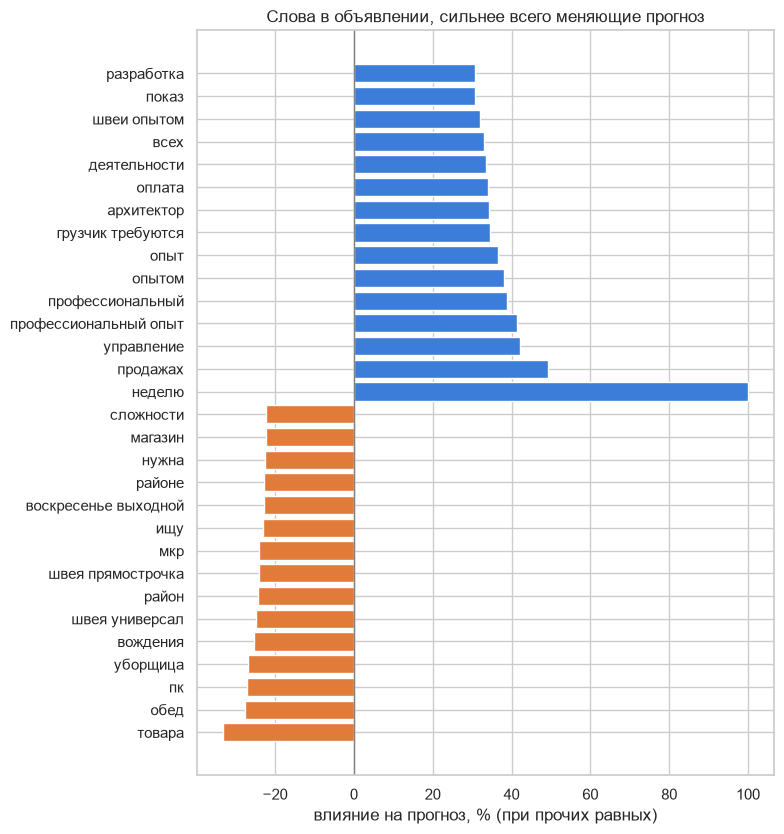

In [8]:
model = build(p).fit(d[COLS], d.y)
ct, ridge = model[0], model[1]
names = ct.get_feature_names_out()
coef = pd.Series(ridge.coef_, index=names)

words = coef[coef.index.str.startswith("t__")]
words.index = words.index.str.replace("t__", "", regex=False)
top = pd.concat([words.nsmallest(15), words.nlargest(15)])
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(top.index, (np.exp(top) - 1) * 100, color=np.where(top > 0, "#3b7dd8", "#e07b39"))
ax.axvline(0, color="grey", lw=1); ax.set_xlabel("влияние на прогноз, % (при прочих равных)")
ax.set_title("Слова в объявлении, сильнее всего меняющие прогноз")
plt.tight_layout(); plt.savefig(FIG + "04_words.png", dpi=150); plt.show()

In [9]:
cats = coef[coef.index.str.startswith("cat__")]
cats.index = cats.index.str.replace("cat__", "", regex=False)
show = pd.concat([cats.nsmallest(8), cats.nlargest(8)])
((np.exp(show) - 1) * 100).round(1).rename("влияние, %").to_frame()

,"влияние, %"
sub_category_Электромонтажник,-35.2
sub_category_Охранник,-26.4
sub_category_Кредитный специалист,-25.7
sub_category_Диспетчер,-25.3
sub_category_Грузчик,-24.6
sub_category_Зоотехник,-23.4
sub_category_Разнорабочий,-22.7
"category_Домашний, обслуживающий персонал",-21.8
category_Работа за границей,63.0
sub_category_Технолог,59.2


In [10]:
nums = coef[coef.index.str.startswith("num__")]
nums.index = nums.index.str.replace("num__", "", regex=False)
print("Числовые признаки (влияние при изменении на 1 стандартное отклонение):")
((np.exp(nums) - 1) * 100).round(1).rename("влияние, %").to_frame()

Числовые признаки (влияние при изменении на 1 стандартное отклонение):


,"влияние, %"
experience_start,4.7
n_skills,1.4
text_len,4.1
remote,-0.6
commission,-0.3
kyrgyz_text,0.1


## 6. Где модели можно доверять

In [11]:
trust = pd.DataFrame({
    "группа": ["типичные зарплаты 25–60 тыс.", "низкие зарплаты < 25 тыс.", "высокие зарплаты 60–100 тыс.",
               "очень высокие 100 тыс.+", "hh", "lalafo"],
    "доля прогнозов с ошибкой < 20%": [
        d.loc[d.real.between(25_000, 60_000), "rel"].lt(.2).mean(),
        d.loc[d.real < 25_000, "rel"].lt(.2).mean(),
        d.loc[d.real.between(60_000, 100_000), "rel"].lt(.2).mean(),
        d.loc[d.real >= 100_000, "rel"].lt(.2).mean(),
        d.loc[d.source == "headhunter", "rel"].lt(.2).mean(),
        d.loc[d.source == "lalafo", "rel"].lt(.2).mean(),
    ],
}).set_index("группа")
trust.style.format("{:.0%}")

,доля прогнозов с ошибкой < 20%
группа,
типичные зарплаты 25–60 тыс.,53%
низкие зарплаты < 25 тыс.,18%
высокие зарплаты 60–100 тыс.,30%
очень высокие 100 тыс.+,16%
hh,42%
lalafo,41%


## Выводы

1. **Модель надёжна для типичных зарплат.** В диапазоне 25–60 тыс. сом больше половины прогнозов
   (53–56%) ошибаются меньше чем на 20%. Для низких (< 25 тыс.) и очень высоких (100 тыс.+) зарплат
   таких прогнозов только 15–21%: модель тянет прогноз к середине (завышает низкие на ~48%,
   занижает очень высокие на ~46%).
2. **Точность зависит от профессии.** Лучше всего предсказываются офис-менеджеры, продавцы,
   торговые представители, повара (50–60% прогнозов в пределах 20%). Хуже всего: швеи (20%),
   агенты по недвижимости, программисты. В этих профессиях зарплата сильно зависит от объёма
   работы, процента или уровня, которых нет в данных.
3. **Чем опытнее вакансия, тем хуже прогноз:** 6+ лет: 33% прогнозов в пределах 20% против 40–43%
   для вакансий без опыта и с опытом 1–3 года. Именно эти вакансии чаще скрывают зарплату (H1 в анализе).
4. **hh и lalafo предсказываются одинаково** (43% и 40% в пределах 20%).
5. **Модель понятна.** Сильнее всего прогноз повышают категория «работа за границей» и
   «высший менеджмент» (+62%), профессии технолог (+58%) и водитель (+42%), слова «опыт», «управление»,
   «продажах», «разработка», «архитектор». Понижают: электромонтажник, охранник, грузчик (−25…−35%),
   слова «товара», «обед», «уборщица», «пк», «швея».
6. **Найдена и исправлена утечка.** В первой версии самыми сильными «словами» были числа
   («500 сом», «15000»): модель читала зарплату прямо из текста. После удаления чисел и валют
   из текста оценки стали честными, а слова в списке выше осмысленными.

**Где модели можно доверять:** как ориентир по рынку для типичных вакансий; для редких дорогих
позиций и сдельной оплаты прогноз стоит считать нижней оценкой.